Libraries imported successfully!

========== DATASET INFORMATION ==========
Dataset Shape: (569, 30)
Number of Features: 30
Number of Records: 569

Target Classes:
['malignant' 'benign']

First Five Records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414

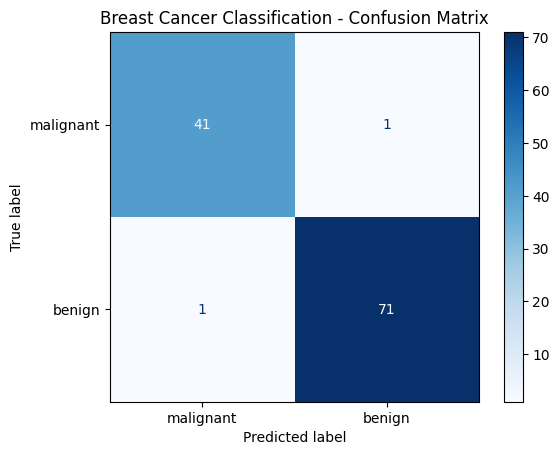


========== PROJECT CONCLUSION ==========
Baseline Accuracy: 0.9474
Cross Validation Mean: 0.9765
Tuned Validation Accuracy: 0.9912
Final Test Accuracy: 0.9825

The tuned model improved validation accuracy.

GridSearchCV selected the best hyperparameter.
StandardScaler helped standardize the input features.
The final model was evaluated using unseen test data.

========== PROJECT COMPLETED SUCCESSFULLY ==========


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
print("Libraries imported successfully!")
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("\n========== DATASET INFORMATION ==========")
print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Records:", X.shape[0])

print("\nTarget Classes:")
print(dataset.target_names)

print("\nFirst Five Records:")
print(X.head())

print("\nClass Distribution:")
print(y.value_counts())
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=42,
    stratify=y_temp
)

print("\n========== DATA SPLITTING ==========")
print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)
baseline_model = LogisticRegression(max_iter=10000)

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_val)

baseline_accuracy = accuracy_score(
    y_val, baseline_pred
)

print("\n========== BASELINE MODEL ==========")
print("Baseline Accuracy:", round(baseline_accuracy, 4))
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=10000))
])

cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("\n========== 5-FOLD CROSS VALIDATION ==========")

for i, score in enumerate(cv_scores, start=1):
    print("Fold", i, "Accuracy:", round(score, 4))

cv_mean = cv_scores.mean()

print("Mean Cross Validation Accuracy:", round(cv_mean, 4))
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=10000))
])

pipeline.fit(X_train, y_train)

pipeline_pred = pipeline.predict(X_val)

pipeline_accuracy = accuracy_score(
    y_val, pipeline_pred
)

print("\n========== PIPELINE MODEL ==========")
print("Pipeline Validation Accuracy:", round(pipeline_accuracy, 4))
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("\n========== GRID SEARCH RESULTS ==========")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Score:",
      round(grid_search.best_score_, 4))

tuned_pred = best_model.predict(X_val)

tuned_accuracy = accuracy_score(
    y_val, tuned_pred
)

print("\n========== TUNED MODEL ==========")
print("Tuned Validation Accuracy:", round(tuned_accuracy, 4))

X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

best_model.fit(X_final_train, y_final_train)

final_pred = best_model.predict(X_test)

final_accuracy = accuracy_score(
    y_test, final_pred
)

print("\n========== FINAL TEST RESULTS ==========")
print("Final Test Accuracy:", round(final_accuracy, 4))
comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "5-Fold Cross Validation Mean",
        "StandardScaler + Logistic Regression",
        "Tuned Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        cv_mean,
        pipeline_accuracy,
        tuned_accuracy
    ]
})

print("\n========== MODEL COMPARISON TABLE ==========")
print(comparison.to_string(index=False))
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_test,
    final_pred,
    target_names=dataset.target_names
))
cm = confusion_matrix(y_test, final_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.target_names
)

display.plot(cmap="Blues")
plt.title("Breast Cancer Classification - Confusion Matrix")
plt.show()
print("\n========== PROJECT CONCLUSION ==========")

print("Baseline Accuracy:", round(baseline_accuracy, 4))
print("Cross Validation Mean:", round(cv_mean, 4))
print("Tuned Validation Accuracy:", round(tuned_accuracy, 4))
print("Final Test Accuracy:", round(final_accuracy, 4))

if tuned_accuracy > baseline_accuracy:
    print("\nThe tuned model improved validation accuracy.")
elif tuned_accuracy == baseline_accuracy:
    print("\nBoth models achieved the same validation accuracy.")
else:
    print("\nThe tuned model did not improve validation accuracy.")

print("\nGridSearchCV selected the best hyperparameter.")
print("StandardScaler helped standardize the input features.")
print("The final model was evaluated using unseen test data.")

print("\n========== PROJECT COMPLETED SUCCESSFULLY ==========")